# Regularisation and tuning neural networks — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D019_Keras_tuner_lesson.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

In [2]:
import tensorflow as tf 
import pandas as pd 
import numpy as np 
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [ ]:
# TODO: compute `column_names`, `url`, `df`
# Name your result: column_names, url, df

In [4]:
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [5]:
(df.astype(str) == '?').any()

age         False
sex         False
cp          False
trestbps    False
chol        False
fbs         False
restecg     False
thalach     False
exang       False
oldpeak     False
slope       False
ca           True
thal         True
target      False
dtype: bool

In [ ]:
# TODO: call `.replace()`

In [ ]:
# TODO: call `pd.to_numeric`

In [8]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

In [ ]:
# TODO: compute `df`
# Name your result: df

In [ ]:
# TODO: call `.astype()` on `target`

In [11]:
df.target.value_counts()

target
0    160
1    137
Name: count, dtype: int64

In [12]:
df['target'].value_counts()

target
0    160
1    137
Name: count, dtype: int64

In [13]:
# df.isna().sum()

In [ ]:
# TODO: compute `X`, `y` from `target`
# Name your result: X, y

In [ ]:
# TODO: call `train_test_split`

In [16]:
df.info()

<class 'pandas.DataFrame'>
Index: 297 entries, 0 to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    float64
 1   sex       297 non-null    float64
 2   cp        297 non-null    float64
 3   trestbps  297 non-null    float64
 4   chol      297 non-null    float64
 5   fbs       297 non-null    float64
 6   restecg   297 non-null    float64
 7   thalach   297 non-null    float64
 8   exang     297 non-null    float64
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    float64
 11  ca        297 non-null    float64
 12  thal      297 non-null    float64
 13  target    297 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 34.8 KB


In [ ]:
# TODO: compute `scaler`, `X_train_s`, `X_test_s`
# Name your result: scaler, X_train_s, X_test_s

In [ ]:
# TODO: compute `baseline_model` from `accuracy`
# Name your result: baseline_model

In [ ]:
# TODO: compute `history_baseline`, `epochs`, `batch_size`
# Name your result: history_baseline, epochs, batch_size, validation_split

In [ ]:
# TODO: draw a `plt.figure` of `accuracy`
# Name your result: final_train_acc, final_val_acc, gap

In [ ]:
# TODO: call `baseline_model.evaluate`

In [ ]:
# TODO: compute `y_pred_prob`
# Name your result: y_pred_prob

In [ ]:
# TODO: compute `y_pred`
# Name your result: y_pred

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

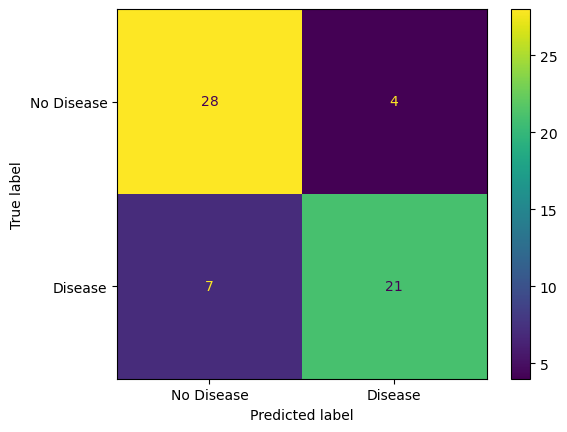

In [25]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=['No Disease','Disease'])

In [26]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      0.88      0.84        32
           1       0.84      0.75      0.79        28

    accuracy                           0.82        60
   macro avg       0.82      0.81      0.81        60
weighted avg       0.82      0.82      0.82        60



In [ ]:
# TODO: compute `dropout_model`, `optimizer`, `loss` from `accuracy`
# Name your result: dropout_model, optimizer, loss, metrics

In [ ]:
# TODO: compute `early_stop`, `monitor`, `patience`
# Name your result: early_stop, monitor, patience, restore_best_weights

In [ ]:
# TODO: draw a `plt.figure` of `accuracy`

In [ ]:
# TODO: compute `bn_model`, `optimizer`, `loss` from `accuracy`
# Name your result: bn_model, optimizer, loss, metrics

In [ ]:
# TODO: compute `lr_scheduler`, `monitor`, `factor`
# Name your result: lr_scheduler, monitor, factor, patience

In [ ]:
# TODO: compute `model`, `history`, `epochs` from `accuracy`, `val_loss`, `val_accuracy`
# Name your result: model, history, epochs, batch_size

In [ ]:
# ═══ CHECKPOINT — "Functional API" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'
df = pd.read_csv(url, names=column_names)
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna()
df['target'] = (df['target'] > 0).astype(int)
X = df.drop('target', axis=1).values
y = df['target'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
baseline_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dense(8, activation='relu'), tf.keras.layers.Dense(1, activation='sigmoid')])
baseline_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_baseline = baseline_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, verbose=1)
final_train_acc = history_baseline.history['accuracy'][-1]
final_val_acc = history_baseline.history['val_accuracy'][-1]
gap = final_train_acc - final_val_acc
test_loss, test_acc = baseline_model.evaluate(X_test_s, y_test, verbose=0)
y_pred_prob = baseline_model.predict(X_test_s)
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
dropout_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')], name='Dropout_Model')
dropout_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
history_dropout = dropout_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[early_stop], verbose=1)
test_loss_dropout, test_acc_dropout = dropout_model.evaluate(X_test_s, y_test, verbose=0)
bn_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')], name='BatchNorm_Model')
bn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-05, verbose=1)
early_stop_bn = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)
history_bn = bn_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[lr_scheduler, early_stop_bn], verbose=1)
def train_with_optimizer(optimizer_name, optimizer, model_name):
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')])
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    history = model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, verbose=0)
    return (history, model)
hist_sgd, model_sgd = train_with_optimizer('SGD', tf.keras.optimizers.SGD(learning_rate=0.01), 'SGD_Model')
hist_rmsprop, model_rmsprop = train_with_optimizer('RMSprop', tf.keras.optimizers.RMSprop(learning_rate=0.001), 'RMSprop_Model')
hist_adam, model_adam = train_with_optimizer('Adam', tf.keras.optimizers.Adam(learning_rate=0.001), 'Adam_Model')
best_optimizer = max([('SGD', hist_sgd.history['val_accuracy'][-1]), ('RMSprop', hist_rmsprop.history['val_accuracy'][-1]), ('Adam', hist_adam.history['val_accuracy'][-1])], key=lambda x: x[1])

print("Checkpoint restored. Ready for: Functional API")

### Functional API

In [33]:
import tensorflow.keras as tf

In [53]:
df['target'].value_counts()

target
0    160
1    137
Name: count, dtype: int64

In [55]:
# df.head()

In [ ]:
# TODO: compute `input_`, `hidden1`, `hidden2` from `accuracy`
# Name your result: input_, hidden1, hidden2, output

In [ ]:
# TODO: draw a `plt.figure` of `accuracy`

In [ ]:
# ═══ CHECKPOINT — "model saving and loading" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'
df = pd.read_csv(url, names=column_names)
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna()
df['target'] = (df['target'] > 0).astype(int)
X = df.drop('target', axis=1).values
y = df['target'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
baseline_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dense(8, activation='relu'), tf.keras.layers.Dense(1, activation='sigmoid')])
baseline_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_baseline = baseline_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, verbose=1)
final_train_acc = history_baseline.history['accuracy'][-1]
final_val_acc = history_baseline.history['val_accuracy'][-1]
gap = final_train_acc - final_val_acc
test_loss, test_acc = baseline_model.evaluate(X_test_s, y_test, verbose=0)
y_pred_prob = baseline_model.predict(X_test_s)
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
dropout_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')], name='Dropout_Model')
dropout_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
history_dropout = dropout_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[early_stop], verbose=1)
test_loss_dropout, test_acc_dropout = dropout_model.evaluate(X_test_s, y_test, verbose=0)
bn_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')], name='BatchNorm_Model')
bn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-05, verbose=1)
early_stop_bn = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)
history_bn = bn_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[lr_scheduler, early_stop_bn], verbose=1)
def train_with_optimizer(optimizer_name, optimizer, model_name):
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')])
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    history = model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, verbose=0)
    return (history, model)
hist_sgd, model_sgd = train_with_optimizer('SGD', tf.keras.optimizers.SGD(learning_rate=0.01), 'SGD_Model')
hist_rmsprop, model_rmsprop = train_with_optimizer('RMSprop', tf.keras.optimizers.RMSprop(learning_rate=0.001), 'RMSprop_Model')
hist_adam, model_adam = train_with_optimizer('Adam', tf.keras.optimizers.Adam(learning_rate=0.001), 'Adam_Model')
best_optimizer = max([('SGD', hist_sgd.history['val_accuracy'][-1]), ('RMSprop', hist_rmsprop.history['val_accuracy'][-1]), ('Adam', hist_adam.history['val_accuracy'][-1])], key=lambda x: x[1])
import tensorflow.keras as tf
input_ = tf.layers.Input(shape=(13,))
hidden1 = tf.layers.Dense(30, activation='relu')(input_)
hidden2 = tf.layers.Dense(30, activation='relu')(hidden1)
output = tf.layers.Dense(1, activation='sigmoid')(hidden2)
model = tf.Model(inputs=input_, outputs=output)
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
history = model.fit(X_train_s, y_train, epochs=1, validation_data=(X_test_s, y_test))
test_loss, test_acc = model.evaluate(X_test_s, y_test, verbose=0)

print("Checkpoint restored. Ready for: model saving and loading")

### model saving and loading

In [36]:
model.save('../../00-data/api_model.keras')


In [37]:
import os
os.getcwd()

'/Users/subashanannair/Documents/00_forward/COHORTS/16_MARCH_2026/MicroCredential_2026/05_Deep_Learning/01_Neural_Network/06_Case_Studies'

In [ ]:
# TODO: compute `loaded_model`
# Name your result: loaded_model

In [41]:
loaded_loss,loaded_acc = loaded_model.evaluate(X_test_s,y_test,verbose=2)

2/2 - 0s - 74ms/step - accuracy: 0.7833 - loss: 0.4185


In [57]:
y_pred_proba = loaded_model.predict(X_test_s[:1])
y_pred = (y_pred_proba>=0.5).astype(int).flatten()
print(y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
[1]


In [ ]:
# ═══ CHECKPOINT — "model checkpoint" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'
df = pd.read_csv(url, names=column_names)
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna()
df['target'] = (df['target'] > 0).astype(int)
X = df.drop('target', axis=1).values
y = df['target'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
baseline_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dense(8, activation='relu'), tf.keras.layers.Dense(1, activation='sigmoid')])
baseline_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_baseline = baseline_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, verbose=1)
final_train_acc = history_baseline.history['accuracy'][-1]
final_val_acc = history_baseline.history['val_accuracy'][-1]
gap = final_train_acc - final_val_acc
test_loss, test_acc = baseline_model.evaluate(X_test_s, y_test, verbose=0)
y_pred_prob = baseline_model.predict(X_test_s)
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
dropout_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')], name='Dropout_Model')
dropout_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
history_dropout = dropout_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[early_stop], verbose=1)
test_loss_dropout, test_acc_dropout = dropout_model.evaluate(X_test_s, y_test, verbose=0)
bn_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')], name='BatchNorm_Model')
bn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-05, verbose=1)
early_stop_bn = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)
history_bn = bn_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[lr_scheduler, early_stop_bn], verbose=1)
def train_with_optimizer(optimizer_name, optimizer, model_name):
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')])
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    history = model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, verbose=0)
    return (history, model)
hist_sgd, model_sgd = train_with_optimizer('SGD', tf.keras.optimizers.SGD(learning_rate=0.01), 'SGD_Model')
hist_rmsprop, model_rmsprop = train_with_optimizer('RMSprop', tf.keras.optimizers.RMSprop(learning_rate=0.001), 'RMSprop_Model')
hist_adam, model_adam = train_with_optimizer('Adam', tf.keras.optimizers.Adam(learning_rate=0.001), 'Adam_Model')
best_optimizer = max([('SGD', hist_sgd.history['val_accuracy'][-1]), ('RMSprop', hist_rmsprop.history['val_accuracy'][-1]), ('Adam', hist_adam.history['val_accuracy'][-1])], key=lambda x: x[1])
import tensorflow.keras as tf
input_ = tf.layers.Input(shape=(13,))
hidden1 = tf.layers.Dense(30, activation='relu')(input_)
hidden2 = tf.layers.Dense(30, activation='relu')(hidden1)
output = tf.layers.Dense(1, activation='sigmoid')(hidden2)
model = tf.Model(inputs=input_, outputs=output)
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
history = model.fit(X_train_s, y_train, epochs=1, validation_data=(X_test_s, y_test))
test_loss, test_acc = model.evaluate(X_test_s, y_test, verbose=0)
model.save('../../00-data/api_model.keras')
import os
loaded_model = tf.models.load_model('../../00-data/api_model.keras')
loaded_loss, loaded_acc = loaded_model.evaluate(X_test_s, y_test, verbose=2)
y_pred_proba = loaded_model.predict(X_test_s[:1])
y_pred = (y_pred_proba >= 0.5).astype(int).flatten()

print("Checkpoint restored. Ready for: model checkpoint")

### model checkpoint

In [ ]:
# TODO: compute `checkpoint`, `input_`, `hidden1` from `accuracy`
# Name your result: checkpoint, input_, hidden1, hidden2

In [ ]:
# TODO: compute `cp_model`
# Name your result: cp_model

### Keras tuner (hyper parameter)

In [63]:
import keras_tuner as kt


In [ ]:
# TODO: compute `model`, `input_`, `hp_unit_1` from `accuracy`
# Name your result: model, input_, hp_unit_1, hp_dropout

In [71]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,
    directory='heart_disease_tuning',
    project_name='heart_disease_tuning'
)
tuner.search_space_summary()

Reloading Tuner from heart_disease_tuning/heart_disease_tuning/tuner0.json
Search space summary
Default search space size: 4
units_layer_1 (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 64, 128], 'ordered': True}
dropout_rate (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
units_layer_2 (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 64, 128], 'ordered': True}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 1e-05], 'ordered': True}


In [ ]:
# TODO: compute `epochs`, `batch_size`, `validation_split`
# Name your result: epochs, batch_size, validation_split, callbacks

In [75]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

In [77]:
print(best_hps.get('units_layer_1'))
print(best_hps.get('units_layer_2'))
print(best_hps.get('dropout_rate'))
print(best_hps.get('learning_rate'))

64
128
0.2
0.001


In [ ]:
# ═══ CHECKPOINT — "building and evaluating the best model" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import tensorflow as tf
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'
df = pd.read_csv(url, names=column_names)
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna()
df['target'] = (df['target'] > 0).astype(int)
X = df.drop('target', axis=1).values
y = df['target'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=67, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
baseline_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dense(8, activation='relu'), tf.keras.layers.Dense(1, activation='sigmoid')])
baseline_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_baseline = baseline_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, verbose=1)
final_train_acc = history_baseline.history['accuracy'][-1]
final_val_acc = history_baseline.history['val_accuracy'][-1]
gap = final_train_acc - final_val_acc
test_loss, test_acc = baseline_model.evaluate(X_test_s, y_test, verbose=0)
y_pred_prob = baseline_model.predict(X_test_s)
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
dropout_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(16, activation='relu'), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')], name='Dropout_Model')
dropout_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
history_dropout = dropout_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[early_stop], verbose=1)
test_loss_dropout, test_acc_dropout = dropout_model.evaluate(X_test_s, y_test, verbose=0)
bn_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')], name='BatchNorm_Model')
bn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-05, verbose=1)
early_stop_bn = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)
history_bn = bn_model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[lr_scheduler, early_stop_bn], verbose=1)
def train_with_optimizer(optimizer_name, optimizer, model_name):
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(13,)), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(32, activation='relu'), tf.keras.layers.BatchNormalization(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(1, activation='sigmoid')])
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    history = model.fit(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, verbose=0)
    return (history, model)
hist_sgd, model_sgd = train_with_optimizer('SGD', tf.keras.optimizers.SGD(learning_rate=0.01), 'SGD_Model')
hist_rmsprop, model_rmsprop = train_with_optimizer('RMSprop', tf.keras.optimizers.RMSprop(learning_rate=0.001), 'RMSprop_Model')
hist_adam, model_adam = train_with_optimizer('Adam', tf.keras.optimizers.Adam(learning_rate=0.001), 'Adam_Model')
best_optimizer = max([('SGD', hist_sgd.history['val_accuracy'][-1]), ('RMSprop', hist_rmsprop.history['val_accuracy'][-1]), ('Adam', hist_adam.history['val_accuracy'][-1])], key=lambda x: x[1])
import tensorflow.keras as tf
input_ = tf.layers.Input(shape=(13,))
hidden1 = tf.layers.Dense(30, activation='relu')(input_)
hidden2 = tf.layers.Dense(30, activation='relu')(hidden1)
output = tf.layers.Dense(1, activation='sigmoid')(hidden2)
model = tf.Model(inputs=input_, outputs=output)
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
history = model.fit(X_train_s, y_train, epochs=1, validation_data=(X_test_s, y_test))
test_loss, test_acc = model.evaluate(X_test_s, y_test, verbose=0)
model.save('../../00-data/api_model.keras')
import os
loaded_model = tf.models.load_model('../../00-data/api_model.keras')
loaded_loss, loaded_acc = loaded_model.evaluate(X_test_s, y_test, verbose=2)
y_pred_proba = loaded_model.predict(X_test_s[:1])
y_pred = (y_pred_proba >= 0.5).astype(int).flatten()
checkpoint = tf.callbacks.ModelCheckpoint('../../00-data/model_checkpoint.keras', monitor='val_accuracy', save_best_only=True, mode='max', verbose=2)
input_ = tf.layers.Input(shape=(13,))
hidden1 = tf.layers.Dense(30, activation='relu')(input_)
hidden2 = tf.layers.Dense(30, activation='relu')(hidden1)
output = tf.layers.Dense(1, activation='sigmoid')(hidden2)
cp_model = tf.Model(inputs=input_, outputs=output)
cp_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
history = cp_model.fit(X_train_s, y_train, epochs=1, validation_data=(X_test_s, y_test), callbacks=[checkpoint])
cp_model = tf.models.load_model('../../00-data/model_checkpoint.keras')
loss, acc = cp_model.evaluate(X_test_s, y_test)
import keras_tuner as kt
def build_model(hp):
    model = tf.Sequential()
    input_ = tf.layers.Input(shape=(13,))
    model.add(input_)
    hp_unit_1 = hp.Choice('units_layer_1', values=[16, 32, 64, 128])
    model.add(tf.layers.Dense(hp_unit_1, activation='relu'))
    hp_dropout = hp.Float('dropout_rate', min_value=0.0, max_value=0.5, step=0.1)
    model.add(tf.layers.Dropout(hp_dropout))
    hp_unit_2 = hp.Choice('units_layer_2', values=[16, 32, 64, 128])
    model.add(tf.layers.Dense(hp_unit_2, activation='relu'))
    model.add(tf.layers.Dense(1, activation='sigmoid'))
    hp_lr = hp.Choice('learning_rate', values=[0.01, 0.001, 1e-05])
    model.compile(optimizer=tf.optimizers.Adam(learning_rate=hp_lr), loss='binary_crossentropy', metrics=['accuracy'])
    return model
tuner = kt.RandomSearch(build_model, objective='val_accuracy', max_trials=1, directory='heart_disease_tuning', project_name='heart_disease_tuning')
tuner.search(X_train_s, y_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[tf.callbacks.EarlyStopping(patience=5, restore_best_weights=True)], verbose=1)
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Checkpoint restored. Ready for: building and evaluating the best model")

### building and evaluating the best model

In [ ]:
# TODO: compute `best_tuned_model`, `history_tuned`, `epochs`
# Name your result: best_tuned_model, history_tuned, epochs, batch_size

In [80]:
loss,acc = best_tuned_model.evaluate(X_test_s,y_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8333 - loss: 0.3996
